# 03 · Statistical Tests: BEV vs. ICE
**BEV vs. ICE Motor Property Insurance**

Before building pricing models (notebook 04) we test which BEV/ICE differences are statistically significant. There are four tests, each in the standard $H_0$ vs. $H_1$ format:

| | Topic | Parameter compared | Test |
|---|---|---|---|
| **Test 1** | Claim frequency | $\lambda$ = claims per vehicle-year | Exact Poisson rate test |
| **Test 2** | Own-damage severity | $\mu$ = mean of log own-damage cost | Welch t-test (Wilcoxon as a check) |
| **Test 3** | Total-loss rate | $\pi$ = share of claims written off | Two-proportion test |
| **Test 4** | Third-party damage severity | $\mu$ = mean of log third-party cost | Welch t-test (Wilcoxon as a check) |

All tests are two-sided at significance level $\alpha = 0.05$. Decision rule: **reject $H_0$ in favour of $H_1$ if $p < 0.05$**, otherwise fail to reject $H_0$.

**Comparing like with like.** BEVs in this portfolio are much newer and more expensive than ICE cars (notebook 01). So each test is run on:
- **(a) all ages:** the raw comparison;
- **(b) age ≤ 5:** only vehicle ages where both powertrains have real exposure;
- **(c) age ≤ 5 within value tiers** (< ₪75k, ₪75–150k, ₪150k+), where the sample allows it.

**Data:** `data/processed/policies_cleaned.rds` and `claims_cleaned.rds` (run `src/01_clean_datasets.R` first). BEV vs. ICE only; Hybrid is dropped.

## 1. Setup and Data

In [1]:
suppressWarnings(suppressPackageStartupMessages({
  library(tidyverse)
  library(scales)
}))

options(repr.plot.width = 10, repr.plot.height = 5, repr.plot.res = 110,
        dplyr.summarise.inform = FALSE)
theme_set(theme_minimal(base_size = 12))

# Path to a file in data/processed/; works from notebooks/ or the repository root
processed_path <- function(file) {
  path <- file.path(c("../data/processed", "data/processed"), file) |> keep(file.exists) |> first()
  if (is.na(path)) stop("Cannot find ", file, " (run src/01_clean_datasets.R first)")
  path
}

alpha  <- 0.05
fmt_p  <- function(p) if_else(p < 0.001, "< 0.001", number(p, accuracy = 0.001))
fmt_ci <- function(lo, hi, acc = 0.01) paste0(number(lo, acc), " – ", number(hi, acc))
decide <- function(p) if_else(p < alpha, "Reject H0 in favour of H1", "Fail to reject H0")

### 1.1 Analysis data
- **Policies:** BEV and ICE only, with a value tier added. BEV is the first factor level, so every estimate reads "BEV compared with ICE".
- **Claims:** claims inside the policy period, joined many-to-one on `Policy_ID`. The join is checked in `src/02_verify_join.R`. The 2025-01-19 storm is left out, since a one-off catastrophe is priced separately.
- **Samples per test:**
  - **Tests 1–3** use own-damage claims (`Own_Damage_Amount > 0`).
  - **Test 2** also drops amounts above 2 × vehicle value, which look like entry errors.
  - **Test 3** drops theft, because a stolen car is written off whatever its powertrain.
  - **Test 4** uses collisions with a third party and `TP_Damage_Amount > 0`, including claims where the insured car itself had no damage.

In [2]:
policies <- read_rds(processed_path("policies_cleaned.rds")) |>
  filter(Powertrain %in% c("BEV", "ICE")) |>
  mutate(Powertrain = factor(as.character(Powertrain), levels = c("BEV", "ICE")),
         value_tier = cut(Vehicle_Value, c(0, 75e3, 150e3, Inf), right = FALSE,
                          labels = c("Low (<75k)", "Medium (75-150k)", "High (150k+)")))

# All non-storm claims inside the policy period, BEV/ICE policies only
claims_all <- read_rds(processed_path("claims_cleaned.rds")) |>
  filter(!is_cat_event) |>
  inner_join(select(policies, Policy_ID, Powertrain, Start_Date, End_Date,
                    Vehicle_Age, Vehicle_Value, value_tier),
             by = "Policy_ID", relationship = "many-to-one") |>
  filter(between(Accident_Date, Start_Date, End_Date))

od_claims <- claims_all |> filter(Own_Damage_Amount > 0)

# Test 1: one row per policy with its own-damage claim count (0 if none)
freq_data <- policies |>
  left_join(count(od_claims, Policy_ID, name = "n_claims"), by = "Policy_ID") |>
  mutate(n_claims = coalesce(n_claims, 0L))

# Test 2: own-damage claims with a plausible amount
sev_data <- od_claims |> filter(Own_Damage_Amount <= 2 * Vehicle_Value | is.na(Vehicle_Value))

# Test 3: own-damage claims other than theft
tl_data <- od_claims |> filter(Claim_Type != "Theft")

# Test 4: collisions with positive third-party damage
tp_data <- claims_all |> filter(Claim_Type == "Collision_With_TP", TP_Damage_Amount > 0)

tibble(sample = c("Test 1: policies", "Test 2: own-damage claims", "Test 3: claims excl. theft", "Test 4: TP collisions"),
       BEV = c(sum(freq_data$Powertrain == "BEV"), sum(sev_data$Powertrain == "BEV"),
               sum(tl_data$Powertrain == "BEV"), sum(tp_data$Powertrain == "BEV")),
       ICE = c(sum(freq_data$Powertrain == "ICE"), sum(sev_data$Powertrain == "ICE"),
               sum(tl_data$Powertrain == "ICE"), sum(tp_data$Powertrain == "ICE")))

sample,BEV,ICE
<chr>,<int>,<int>
Test 1: policies,4196,25850
Test 2: own-damage claims,631,3704
Test 3: claims excl. theft,626,3577
Test 4: TP collisions,251,1432


## 2. Comparability: the Age ≤ 5 Cohort
ICE cars in the portfolio go up to 20+ years old, while BEVs are almost all new. Comparing the two groups directly compares new cars with old ones. The table shows where BEVs actually have exposure.

In [3]:
freq_data |>
  mutate(age = if_else(Vehicle_Age >= 10, "10+", as.character(Vehicle_Age)),
         age = fct_inseq(age) |> fct_relevel("10+", after = Inf)) |>
  summarise(exposure = sum(exposure), .by = c(age, Powertrain)) |>
  pivot_wider(names_from = Powertrain, values_from = exposure, values_fill = 0) |>
  select(age, BEV, ICE) |>
  arrange(age) |>
  mutate(BEV_share_of_BEV = percent(BEV / sum(BEV), 0.1),
         across(c(BEV, ICE), ~ comma(.x, 1)))

age,BEV,ICE,BEV_share_of_BEV
<fct>,<chr>,<chr>,<chr>
0,826,142,20.8%
1,"1,117","1,025",28.1%
2,739,"1,790",18.6%
3,442,"2,268",11.1%
4,294,"2,457",7.4%
5,206,"2,364",5.2%
6,119,"2,233",3.0%
7,86,"2,096",2.2%
8,48,"1,724",1.2%


BEV exposure stays above 200 vehicle-years per age up to age 5 and then drops sharply. We therefore use **Vehicle_Age ≤ 5** as the comparison cohort.

In [4]:
age_cutoff <- 5

in_cohort <- function(d) filter(d, Vehicle_Age <= age_cutoff)

# What the cohort keeps, and the value mix inside it
in_cohort(freq_data) |>
  summarise(exposure = sum(exposure), mean_age = mean(Vehicle_Age),
            median_value = median(Vehicle_Value, na.rm = TRUE),
            share_high_value = mean(value_tier == "High (150k+)", na.rm = TRUE), .by = Powertrain) |>
  left_join(summarise(freq_data, all_exposure = sum(exposure), .by = Powertrain), by = "Powertrain") |>
  arrange(Powertrain) |>
  transmute(Powertrain,
            share_of_exposure_kept = percent(exposure / all_exposure, 0.1),
            mean_age     = number(mean_age, 0.1),
            median_value = comma(median_value, 1, prefix = "₪"),
            share_high_value = percent(share_high_value, 1))

Powertrain,share_of_exposure_kept,mean_age,median_value,share_high_value
<fct>,<chr>,<chr>,<chr>,<chr>
BEV,91.0%,1.7,"₪147,200",48%
ICE,41.0%,3.3,"₪89,700",9%


Inside the cohort BEVs are still a bit younger and much more often in the high value tier. That is why level (c) also splits by value tier.

### 2.1 Test functions
Each function runs one test on a slice of the data and returns one row: the BEV and ICE figures, the estimate with its 95% CI, the test statistic, the p-value and the decision at $\alpha = 0.05$.

In [5]:
# Exact Poisson test of two claim rates; estimate = rate ratio lambda_BEV / lambda_ICE
rate_test <- function(d) {
  s  <- d |> summarise(claims = sum(n_claims), exposure = sum(exposure), .by = Powertrain) |> arrange(Powertrain)
  pt <- poisson.test(s$claims, s$exposure)
  tibble(bev = s$claims[1] / s$exposure[1], ice = s$claims[2] / s$exposure[2],
         estimate = pt$estimate, ci_low = pt$conf.int[1], ci_high = pt$conf.int[2],
         statistic = paste0("RR = ", number(pt$estimate, 0.01)), p_value = pt$p.value)
}

# Welch t-test on log cost; exp(mean difference) = ratio of geometric means BEV/ICE.
# Wilcoxon rank-sum on the raw amounts checks the result without assuming normality.
log_cost_test <- function(d, amount) {
  d  <- mutate(d, cost = {{ amount }})
  wt <- t.test(log(cost) ~ Powertrain, data = d)
  wx <- wilcox.test(cost ~ Powertrain, data = d, exact = FALSE)
  tibble(n_bev = sum(d$Powertrain == "BEV"), n_ice = sum(d$Powertrain == "ICE"),
         bev = exp(wt$estimate[[1]]), ice = exp(wt$estimate[[2]]),
         estimate = exp(wt$estimate[[1]] - wt$estimate[[2]]),
         ci_low = exp(wt$conf.int[1]), ci_high = exp(wt$conf.int[2]),
         statistic = paste0("t = ", number(wt$statistic, 0.01)), p_value = wt$p.value,
         p_wilcoxon = wx$p.value)
}

# Two-proportion test of the total-loss rate; estimate = pi_BEV - pi_ICE in percentage points
prop_test <- function(d) {
  s  <- d |> summarise(tl = sum(is_total_loss_clean), n = n(), .by = Powertrain) |> arrange(Powertrain)
  pt <- prop.test(s$tl, s$n)
  tibble(n_bev = s$n[1], n_ice = s$n[2], bev = s$tl[1] / s$n[1], ice = s$tl[2] / s$n[2],
         estimate = 100 * (s$tl[1] / s$n[1] - s$tl[2] / s$n[2]),
         ci_low = 100 * pt$conf.int[1], ci_high = 100 * pt$conf.int[2],
         statistic = paste0("X² = ", number(pt$statistic, 0.01)), p_value = pt$p.value)
}

# Run a test on (a) all ages and (b) the age <= 5 cohort
by_level <- function(d, test) {
  list(`(a) All ages` = d, `(b) Age <= 5` = in_cohort(d)) |>
    map(test) |> list_rbind(names_to = "comparison") |> mutate(decision = decide(p_value))
}

# Run a test inside each value tier of the cohort (c)
by_tier <- function(d, test) {
  d <- in_cohort(d) |> filter(!is.na(value_tier))
  split(d, d$value_tier) |> map(test) |> list_rbind(names_to = "tier") |>
    mutate(comparison = paste0("(c) Age <= 5, ", tier), .keep = "unused", .before = 1) |>
    mutate(decision = decide(p_value))
}

## 3. Test 1: Claim Frequency Comparison
**Question:** do BEVs have more own-damage claims per vehicle-year than ICE cars?

Let $\lambda$ be the expected number of claims per vehicle-year.
- $H_0$: $\lambda_{\text{BEV}} = \lambda_{\text{ICE}}$ (no difference in claim frequency)
- $H_1$: $\lambda_{\text{BEV}} \neq \lambda_{\text{ICE}}$

**Test:** exact Poisson rate test (`poisson.test`). It is the standard test for two claim counts observed over different amounts of exposure, and it needs no large-sample approximation. The estimate is the rate ratio $\lambda_{\text{BEV}} / \lambda_{\text{ICE}}$.

In [6]:
freq_results <- bind_rows(by_level(freq_data, rate_test), by_tier(freq_data, rate_test))

freq_results |>
  transmute(comparison, BEV_frequency = percent(bev, 0.01), ICE_frequency = percent(ice, 0.01),
            rate_ratio = number(estimate, 0.01), ci_95 = fmt_ci(ci_low, ci_high),
            p_value = fmt_p(p_value), decision)

comparison,BEV_frequency,ICE_frequency,rate_ratio,ci_95,p_value,decision
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
(a) All ages,15.85%,15.15%,1.05,0.96 – 1.14,0.294,Fail to reject H0
(b) Age <= 5,15.51%,14.63%,1.06,0.96 – 1.17,0.248,Fail to reject H0
"(c) Age <= 5, Low (<75k)",14.74%,16.30%,0.90,0.63 – 1.26,0.625,Fail to reject H0
"(c) Age <= 5, Medium (75-150k)",14.87%,13.77%,1.08,0.93 – 1.25,0.294,Fail to reject H0
"(c) Age <= 5, High (150k+)",16.23%,14.32%,1.13,0.92 – 1.40,0.239,Fail to reject H0


**Decision**
- (a) All ages: $p = 0.294 > 0.05 \implies$ **Fail to reject $H_0$** (RR = 1.05, 95% CI 0.96–1.14).
- (b) Age ≤ 5: $p = 0.248 > 0.05 \implies$ **Fail to reject $H_0$** (RR = 1.06, 95% CI 0.96–1.17).
- (c) Within value tiers: all $p > 0.23 \implies$ **Fail to reject $H_0$** in every tier (RR 0.90–1.13).

**Actuarial takeaway:** BEVs do not claim more often than ICE cars, so no separate BEV frequency loading is needed.

## 4. Test 2: Own-Damage Severity Comparison
**Question:** does a BEV claim cost more to repair than an ICE claim?

Claim costs are strongly right-skewed, but close to normal on the log scale, so we compare mean **log** costs. Let $\mu$ be the mean of $\log(\text{own damage})$.
- $H_0$: $\mu_{\log(\text{OD}),\,\text{BEV}} = \mu_{\log(\text{OD}),\,\text{ICE}}$ (no difference in repair cost)
- $H_1$: $\mu_{\log(\text{OD}),\,\text{BEV}} \neq \mu_{\log(\text{OD}),\,\text{ICE}}$

**Test:** Welch two-sample t-test on log cost, which does not assume equal variances. Back-transformed, the mean difference becomes the **ratio of geometric means**: "a typical BEV claim costs x times a typical ICE claim". The Wilcoxon rank-sum p-value is a check that does not rely on normality.

In [7]:
# Descriptive statistics of own-damage cost
sev_data |>
  group_by(Powertrain) |>
  summarise(claims = n(), mean = mean(Own_Damage_Amount), median = median(Own_Damage_Amount),
            iqr = IQR(Own_Damage_Amount)) |>
  mutate(across(mean:iqr, ~ comma(.x, 1, prefix = "₪")))

Powertrain,claims,mean,median,iqr
<fct>,<int>,<chr>,<chr>,<chr>
BEV,631,"₪20,935","₪9,360","₪19,533"
ICE,3704,"₪11,041","₪4,709","₪8,914"


In [8]:
sev_results <- bind_rows(by_level(sev_data, \(d) log_cost_test(d, Own_Damage_Amount)),
                         by_tier(sev_data,  \(d) log_cost_test(d, Own_Damage_Amount)))

sev_results |>
  transmute(comparison, n_bev, n_ice, cost_ratio = number(estimate, 0.01), ci_95 = fmt_ci(ci_low, ci_high),
            statistic, p_welch = fmt_p(p_value), p_wilcoxon = fmt_p(p_wilcoxon), decision)

comparison,n_bev,n_ice,cost_ratio,ci_95,statistic,p_welch,p_wilcoxon,decision
<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
(a) All ages,631,3704,1.98,1.79 – 2.20,t = 12.98,< 0.001,< 0.001,Reject H0 in favour of H1
(b) Age <= 5,562,1467,1.62,1.44 – 1.83,t = 8.01,< 0.001,< 0.001,Reject H0 in favour of H1
"(c) Age <= 5, Low (<75k)",37,531,1.95,1.25 – 3.03,t = 3.04,0.004,0.001,Reject H0 in favour of H1
"(c) Age <= 5, Medium (75-150k)",242,800,1.30,1.08 – 1.55,t = 2.82,0.005,0.004,Reject H0 in favour of H1
"(c) Age <= 5, High (150k+)",283,135,1.10,0.86 – 1.41,t = 0.80,0.427,0.311,Fail to reject H0


### 4.1 Pooled over value tiers
To get one answer for "same age, similar value" we fit $\log(\text{OD}) = \beta_0 + \beta_{\text{BEV}} \cdot \mathbb{1}\{\text{BEV}\} + \gamma_{\text{tier}}$ on the age ≤ 5 cohort. $\beta_{\text{BEV}}$ is the average BEV/ICE gap *within* tiers.
- $H_0$: $\beta_{\text{BEV}} = 0$ (no BEV cost difference at equal value tier)
- $H_1$: $\beta_{\text{BEV}} \neq 0$

In [9]:
sev_fit <- in_cohort(sev_data) |>
  filter(!is.na(value_tier)) |>
  mutate(Powertrain = fct_relevel(Powertrain, "ICE")) |>
  lm(log(Own_Damage_Amount) ~ Powertrain + value_tier, data = _)

coef_bev <- summary(sev_fit)$coefficients["PowertrainBEV", ]
ci_bev   <- confint(sev_fit)["PowertrainBEV", ]

sev_pooled <- tibble(comparison = "(c) Age <= 5, tiers pooled", estimate = exp(coef_bev[["Estimate"]]),
                     ci_low = exp(ci_bev[[1]]), ci_high = exp(ci_bev[[2]]),
                     statistic = paste0("t = ", number(coef_bev[["t value"]], 0.01)),
                     p_value = coef_bev[["Pr(>|t|)"]], decision = decide(p_value))

sev_pooled |> transmute(comparison, cost_ratio = number(estimate, 0.01), ci_95 = fmt_ci(ci_low, ci_high),
                        statistic, p_value = fmt_p(p_value), decision)

comparison,cost_ratio,ci_95,statistic,p_value,decision
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
"(c) Age <= 5, tiers pooled",1.29,1.13 – 1.48,t = 3.77,< 0.001,Reject H0 in favour of H1


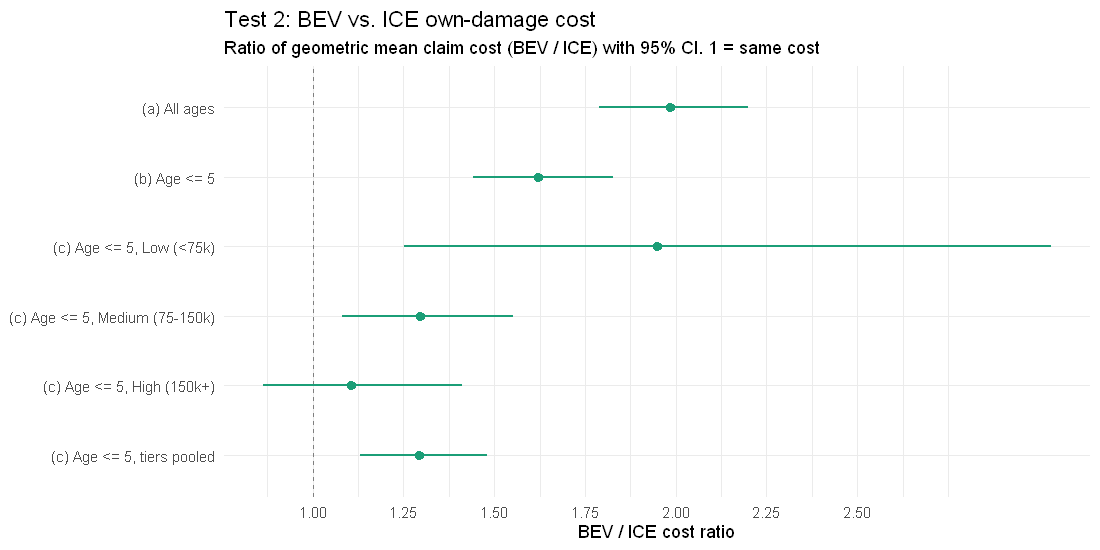

In [10]:
# How the BEV/ICE cost ratio shrinks as the comparison gets fairer
bind_rows(sev_results, sev_pooled) |>
  mutate(comparison = fct_rev(fct_inorder(comparison))) |>
  ggplot(aes(estimate, comparison)) +
  geom_vline(xintercept = 1, linetype = "dashed", colour = "grey50") +
  geom_pointrange(aes(xmin = ci_low, xmax = ci_high), colour = "#1b9e77", linewidth = 0.9) +
  scale_x_continuous(breaks = seq(1, 2.5, 0.25)) +
  labs(title = "Test 2: BEV vs. ICE own-damage cost",
       subtitle = "Ratio of geometric mean claim cost (BEV / ICE) with 95% CI. 1 = same cost",
       x = "BEV / ICE cost ratio", y = NULL)

**Decision**
- (a) All ages: $p < 0.001 < 0.05 \implies$ **Reject $H_0$ in favour of $H_1$**. A typical BEV claim costs 1.98× an ICE claim (95% CI 1.79–2.20).
- (b) Age ≤ 5: $p < 0.001 < 0.05 \implies$ **Reject $H_0$ in favour of $H_1$**, with a cost ratio of 1.62 (1.44–1.83).
- (c) Within value tiers:
  - The low tier ($p = 0.004$) and the medium tier ($p = 0.005$) reject $H_0$.
  - The high tier does not: $p = 0.427 > 0.05 \implies$ fail to reject $H_0$.
  - Pooled over tiers: $p < 0.001 < 0.05 \implies$ **Reject $H_0$ in favour of $H_1$**, cost ratio 1.29 (1.13–1.48).
- The Wilcoxon test gives the same decision in every row, so the result does not depend on the normality assumption.

**Actuarial takeaway:** BEV repairs are more expensive even at the same age and similar value (about +30%), but about half of the raw 2× gap is simply because BEVs are newer and pricier cars.

## 5. Test 3: Total-Loss Rate Comparison
**Question:** when a BEV has a claim, is it more often written off than an ICE car?

Let $\pi$ be the probability that an own-damage claim (excluding theft) is a total loss.
- $H_0$: $\pi_{\text{BEV}} = \pi_{\text{ICE}}$ (no difference in total-loss rate)
- $H_1$: $\pi_{\text{BEV}} \neq \pi_{\text{ICE}}$

**Test:** two-proportion test (`prop.test`). The estimate is $\pi_{\text{BEV}} - \pi_{\text{ICE}}$ in percentage points. Theft is excluded because a stolen car is written off whatever its powertrain. For reference, the rates with theft included are shown first.

In [11]:
# Total-loss rate with and without theft (all ages)
bind_rows(`All own-damage claims` = od_claims, `Excluding theft` = tl_data, .id = "claims") |>
  summarise(total_losses = sum(is_total_loss_clean), n = n(), .by = c(claims, Powertrain)) |>
  mutate(rate = percent(total_losses / n, 0.1)) |>
  select(-total_losses, -n) |>
  pivot_wider(names_from = Powertrain, values_from = rate) |>
  select(claims, BEV, ICE)

claims,BEV,ICE
<chr>,<chr>,<chr>
All own-damage claims,9.0%,10.7%
Excluding theft,8.6%,8.2%


In [12]:
tl_results <- by_level(tl_data, prop_test)

tl_results |>
  transmute(comparison, n_bev, n_ice, BEV_rate = percent(bev, 0.1), ICE_rate = percent(ice, 0.1),
            difference_pp = number(estimate, 0.1), ci_95 = fmt_ci(ci_low, ci_high, 0.1),
            statistic, p_value = fmt_p(p_value), decision)

comparison,n_bev,n_ice,BEV_rate,ICE_rate,difference_pp,ci_95,statistic,p_value,decision
<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
(a) All ages,626,3577,8.6%,8.2%,0.4,-2.1 – 2.9,X² = 0.07,0.793,Fail to reject H0
(b) Age <= 5,557,1415,7.7%,5.7%,2.1,-0.6 – 4.7,X² = 2.58,0.109,Fail to reject H0


### 5.1 Pooled over value tiers
Single value tiers have too few total losses to test one by one (the low tier has only 7 BEV write-offs). We therefore pool the tiers with the **Cochran-Mantel-Haenszel (CMH) test**, the standard test for several 2×2 tables. It compares BEV and ICE *within* each tier and estimates one common odds ratio $\text{OR}_{\text{MH}}$.
- $H_0$: $\text{OR}_{\text{MH}} = 1$ (no BEV/ICE difference in total-loss odds at equal value tier)
- $H_1$: $\text{OR}_{\text{MH}} \neq 1$

In [13]:
tl_cohort <- in_cohort(tl_data) |> filter(!is.na(value_tier))

# Total-loss rates per value tier: rate (total losses / claims)
tl_cohort |>
  summarise(total_losses = sum(is_total_loss_clean), claims = n(), .by = c(value_tier, Powertrain)) |>
  mutate(rate = paste0(percent(total_losses / claims, 0.1), " (", total_losses, "/", claims, ")")) |>
  arrange(Powertrain) |>
  select(value_tier, Powertrain, rate) |>
  pivot_wider(names_from = Powertrain, values_from = rate) |>
  arrange(value_tier)

# Counts as doubles to avoid integer overflow inside mantelhaen.test
cmh_table <- with(tl_cohort, table(Powertrain, factor(is_total_loss_clean, levels = c(TRUE, FALSE)), value_tier))
cmh <- mantelhaen.test(cmh_table * 1)

tl_pooled <- tibble(comparison = "(c) Age <= 5, tiers pooled", estimate = unname(cmh$estimate),
                    ci_low = cmh$conf.int[1], ci_high = cmh$conf.int[2],
                    statistic = paste0("X² = ", number(cmh$statistic, 0.01)),
                    p_value = cmh$p.value, decision = decide(p_value))

tl_pooled |> transmute(comparison, odds_ratio = number(estimate, 0.01), ci_95 = fmt_ci(ci_low, ci_high),
                       statistic, p_value = fmt_p(p_value), decision)

value_tier,BEV,ICE
<fct>,<chr>,<chr>
Low (<75k),18.9% (7/37),5.3% (27/512)
Medium (75-150k),10.0% (24/241),6.2% (48/773)
High (150k+),4.3% (12/279),3.9% (5/129)


comparison,odds_ratio,ci_95,statistic,p_value,decision
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
"(c) Age <= 5, tiers pooled",1.80,1.18 – 2.74,X² = 7.45,0.006,Reject H0 in favour of H1


**Decision**
- (a) All ages: $p = 0.793 > 0.05 \implies$ **Fail to reject $H_0$** (8.6% vs. 8.2%).
- (b) Age ≤ 5: $p = 0.109 > 0.05 \implies$ **Fail to reject $H_0$** (7.7% vs. 5.7%, difference +2.1 pp).
- (c) Pooled over value tiers (CMH): $p = 0.006 < 0.05 \implies$ **Reject $H_0$ in favour of $H_1$**, common OR = 1.80 (1.18–2.74).

**Actuarial takeaway:** at the same age and similar value, BEVs are more likely to be written off. This fits the battery-damage argument, but it rests on few cases (only 7 BEV write-offs in the low tier), so it should be confirmed in the logistic GLM before it is used for pricing.

## 6. Test 4: Third-Party Damage Severity Comparison
**Question:** when a BEV hits another vehicle, does it cause more damage to it than an ICE car does? BEVs are heavier because of the battery, so a collision could transfer more energy to the other car.

Sample: collisions with a third party and positive third-party property damage. Let $\mu$ be the mean of $\log(\text{TP damage})$.
- $H_0$: $\mu_{\log(\text{TP}),\,\text{BEV}} = \mu_{\log(\text{TP}),\,\text{ICE}}$ (no difference in third-party damage)
- $H_1$: $\mu_{\log(\text{TP}),\,\text{BEV}} \neq \mu_{\log(\text{TP}),\,\text{ICE}}$

**Test:** as in Test 2, a Welch t-test on log cost with the Wilcoxon rank-sum test as a check.

In [14]:
# Descriptive statistics of third-party damage, all ages and age <= 5
bind_rows(`(a) All ages` = tp_data, `(b) Age <= 5` = in_cohort(tp_data), .id = "comparison") |>
  group_by(comparison, Powertrain) |>
  summarise(claims = n(), median = median(TP_Damage_Amount), mean = mean(TP_Damage_Amount),
            iqr = IQR(TP_Damage_Amount)) |>
  ungroup() |>
  mutate(across(median:iqr, ~ comma(.x, 1, prefix = "₪")))

comparison,Powertrain,claims,median,mean,iqr
<chr>,<fct>,<int>,<chr>,<chr>,<chr>
(a) All ages,BEV,251,"₪8,265","₪12,194","₪10,879"
(a) All ages,ICE,1432,"₪8,539","₪13,323","₪11,324"
(b) Age <= 5,BEV,233,"₪8,508","₪12,485","₪10,919"
(b) Age <= 5,ICE,556,"₪9,077","₪14,102","₪12,841"


In [15]:
tp_results <- by_level(tp_data, \(d) log_cost_test(d, TP_Damage_Amount))

tp_results |>
  transmute(comparison, n_bev, n_ice, BEV_geo_mean = comma(bev, 1, prefix = "₪"),
            ICE_geo_mean = comma(ice, 1, prefix = "₪"), tp_ratio = number(estimate, 0.01),
            ci_95 = fmt_ci(ci_low, ci_high), statistic, p_welch = fmt_p(p_value),
            p_wilcoxon = fmt_p(p_wilcoxon), decision)

comparison,n_bev,n_ice,BEV_geo_mean,ICE_geo_mean,tp_ratio,ci_95,statistic,p_welch,p_wilcoxon,decision
<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
(a) All ages,251,1432,"₪8,095","₪8,521",0.95,0.84 – 1.07,t = -0.82,0.415,0.414,Fail to reject H0
(b) Age <= 5,233,556,"₪8,321","₪8,905",0.93,0.81 – 1.08,t = -0.94,0.350,0.382,Fail to reject H0


**Decision**
- (a) All ages: $p = 0.415 > 0.05 \implies$ **Fail to reject $H_0$**. Third-party damage caused by BEVs is 0.95× that of ICE cars (95% CI 0.84–1.07).
- (b) Age ≤ 5: $p = 0.350 > 0.05 \implies$ **Fail to reject $H_0$**, with a ratio of 0.93 (0.81–1.08).
- The Wilcoxon test agrees ($p = 0.414$ and $p = 0.382$).
- The medians are almost the same: ₪8,265 vs. ₪8,539 for all ages.

**Actuarial takeaway:** we find no evidence that the extra weight of a BEV leads to higher third-party payouts. If anything the point estimate is slightly below 1, so the third-party part of the premium needs no BEV loading.

## 7. Effect of Comparing Like with Like
The same estimates side by side, from the raw comparison to the fairest one.

In [16]:
show <- function(results, measure) {
  results |> transmute(measure, comparison, estimate = number(estimate, 0.01),
                       ci_95 = fmt_ci(ci_low, ci_high), p_value = fmt_p(p_value))
}

tier_freq <- filter(freq_results, str_starts(comparison, "\\(c\\)"))

bind_rows(
  show(filter(freq_results, !str_starts(comparison, "\\(c\\)")), "Test 1: rate ratio"),
  tibble(measure = "Test 1: rate ratio", comparison = "(c) Age <= 5, each tier",
         estimate = paste(number(range(tier_freq$estimate), 0.01), collapse = " to "), ci_95 = "-",
         p_value = paste("all >", number(floor(min(tier_freq$p_value) * 100) / 100, 0.01))),
  show(bind_rows(filter(sev_results, !str_starts(comparison, "\\(c\\)")), sev_pooled), "Test 2: OD cost ratio"),
  show(tl_results, "Test 3: TL difference (pp)"),
  show(tl_pooled,  "Test 3: TL odds ratio"),
  show(tp_results, "Test 4: TP cost ratio")
)

measure,comparison,estimate,ci_95,p_value
<chr>,<chr>,<chr>,<chr>,<chr>
Test 1: rate ratio,(a) All ages,1.05,0.96 – 1.14,0.294
Test 1: rate ratio,(b) Age <= 5,1.06,0.96 – 1.17,0.248
Test 1: rate ratio,"(c) Age <= 5, each tier",0.90 to 1.13,-,all > 0.23
Test 2: OD cost ratio,(a) All ages,1.98,1.79 – 2.20,< 0.001
Test 2: OD cost ratio,(b) Age <= 5,1.62,1.44 – 1.83,< 0.001
Test 2: OD cost ratio,"(c) Age <= 5, tiers pooled",1.29,1.13 – 1.48,< 0.001
Test 3: TL difference (pp),(a) All ages,0.41,-2.06 – 2.88,0.793
Test 3: TL difference (pp),(b) Age <= 5,2.07,-0.58 – 4.71,0.109
Test 3: TL odds ratio,"(c) Age <= 5, tiers pooled",1.80,1.18 – 2.74,0.006


**Reading the table**
- **Frequency (Test 1) and third-party damage (Test 4)** show no BEV/ICE difference at any level.
- **Own-damage severity (Test 2)** shrinks from about 2.0× to about 1.3× once age and value are matched. Part of what looks like a "BEV effect" is an "expensive new car" effect.
- **Total loss (Test 3)** goes the other way: no difference on raw data, but higher BEV write-off odds at the same age and value.

Driver age and gender are not used as controls: notebook 01 showed they are almost identical for BEV and ICE, so they cannot explain any gap.

**Actuarial takeaway:** vehicle value and vehicle age must be in every pricing model. Otherwise the BEV relativity mixes up powertrain with car age and price.

## 8. Summary of Results
One row per test and comparison level. Decision rule: reject $H_0$ in favour of $H_1$ if $p < 0.05$.

In [17]:
summary_table <- bind_rows(
  filter(freq_results, !str_starts(comparison, "\\(c\\)")) |>
    mutate(test = "Test 1: Claim frequency", h0 = "λ_BEV = λ_ICE",
           takeaway = if_else(p_value < alpha, paste0("Frequency differs (RR ", number(estimate, 0.01), ")"),
                              paste0("No frequency difference (RR ", number(estimate, 0.01), ")"))),
  bind_rows(filter(sev_results, !str_starts(comparison, "\\(c\\)")), sev_pooled) |>
    mutate(test = "Test 2: Own-damage severity", h0 = if_else(str_detect(comparison, "pooled"), "β_BEV = 0", "μ_log(OD),BEV = μ_log(OD),ICE"),
           takeaway = if_else(p_value < alpha, paste0("BEV repair cost ", number(estimate, 0.01), "× ICE"),
                              paste0("No repair cost difference (", number(estimate, 0.01), "×)"))),
  tl_results |>
    mutate(test = "Test 3: Total-loss rate", h0 = "π_BEV = π_ICE",
           takeaway = if_else(p_value < alpha, paste0("BEV write-off rate ", number(estimate, 0.1), " pp vs. ICE"),
                              paste0("No write-off difference (", number(estimate, 0.1), " pp)"))),
  tl_pooled |>
    mutate(test = "Test 3: Total-loss rate", h0 = "OR_MH = 1",
           takeaway = if_else(p_value < alpha, paste0("BEV write-off odds ", number(estimate, 0.01), "× at equal value"),
                              paste0("No write-off difference at equal value (OR ", number(estimate, 0.01), ")"))),
  tp_results |>
    mutate(test = "Test 4: Third-party severity", h0 = "μ_log(TP),BEV = μ_log(TP),ICE",
           takeaway = if_else(p_value < alpha, paste0("BEVs cause ", number(estimate, 0.01), "× the TP damage"),
                              paste0("No TP damage difference (", number(estimate, 0.01), "×)")))
) |>
  transmute(test, comparison, null_hypothesis = h0,
            statistic_p = paste0(statistic, ", p ", if_else(p_value < 0.001, "< 0.001", paste("=", number(p_value, 0.001)))),
            decision, takeaway)

summary_table

# Multiple testing: does a Holm correction over all rows change any decision?
holm <- c(filter(freq_results, !str_starts(comparison, "\\(c\\)"))$p_value,
          filter(sev_results,  !str_starts(comparison, "\\(c\\)"))$p_value, sev_pooled$p_value,
          tl_results$p_value, tl_pooled$p_value, tp_results$p_value)
cat("Holm correction over", length(holm), "tests changes",
    sum((holm < alpha) != (p.adjust(holm, "holm") < alpha)), "decision(s).\n")

test,comparison,null_hypothesis,statistic_p,decision,takeaway
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
Test 1: Claim frequency,(a) All ages,λ_BEV = λ_ICE,"RR = 1.05, p = 0.294",Fail to reject H0,No frequency difference (RR 1.05)
Test 1: Claim frequency,(b) Age <= 5,λ_BEV = λ_ICE,"RR = 1.06, p = 0.248",Fail to reject H0,No frequency difference (RR 1.06)
Test 2: Own-damage severity,(a) All ages,"μ_log(OD),BEV = μ_log(OD),ICE","t = 12.98, p < 0.001",Reject H0 in favour of H1,BEV repair cost 1.98× ICE
Test 2: Own-damage severity,(b) Age <= 5,"μ_log(OD),BEV = μ_log(OD),ICE","t = 8.01, p < 0.001",Reject H0 in favour of H1,BEV repair cost 1.62× ICE
Test 2: Own-damage severity,"(c) Age <= 5, tiers pooled",β_BEV = 0,"t = 3.77, p < 0.001",Reject H0 in favour of H1,BEV repair cost 1.29× ICE
Test 3: Total-loss rate,(a) All ages,π_BEV = π_ICE,"X² = 0.07, p = 0.793",Fail to reject H0,No write-off difference (0.4 pp)
Test 3: Total-loss rate,(b) Age <= 5,π_BEV = π_ICE,"X² = 2.58, p = 0.109",Fail to reject H0,No write-off difference (2.1 pp)
Test 3: Total-loss rate,"(c) Age <= 5, tiers pooled",OR_MH = 1,"X² = 7.45, p = 0.006",Reject H0 in favour of H1,BEV write-off odds 1.80× at equal value
Test 4: Third-party severity,(a) All ages,"μ_log(TP),BEV = μ_log(TP),ICE","t = -0.82, p = 0.415",Fail to reject H0,No TP damage difference (0.95×)


Holm correction over 10 tests changes 0 decision(s).


**Conclusions**
1. **Frequency:** fail to reject $H_0$. BEVs claim as often as ICE cars.
2. **Own-damage severity:** reject $H_0$. BEV repairs cost more, about 1.3× at the same age and value (2.0× raw).
3. **Total loss:** fail to reject $H_0$ on raw data. Reject it once age and value are held fixed (OR 1.80), but the evidence is based on few cases.
4. **Third-party severity:** fail to reject $H_0$. BEVs do not cause more damage to other vehicles.

A Holm correction for testing ten hypotheses at once changes none of these decisions.

**Next step (notebook 04):** GLMs with all rating factors at once:
- **Frequency:** Poisson with `offset(log(exposure))`.
- **Severity:** Gamma with vehicle value as a covariate.
- **Total loss:** logistic.

Based on these tests we expect a BEV relativity of about 1.0 for frequency, about 1.3 for own-damage severity on top of value, and about 1.0 for third-party damage.